# Stopping model: bound, guesses, and choice lapses

**Status (2026-10-09):** model implemented in `pigeon/stopping.py` (tests in
`tests/test_stopping.py`); parameter recovery and fixed-block fits below. The "guess" rate is a catch-all
for commits the bound can't explain (see the interpretation note at the end);
change-point blocks not yet fit.

## Why this notebook

Every bound analysis in the paper treats each trial as a bound crossing and handles
guessing only by filtering (`DT >= 2`, `trial_number >= 10`, the `rt_below_cutoff`
from `get_bounds`). This notebook fits an explicit trial-level model of *when*
subjects stop and *which* side they choose, so that guesses are estimated rather
than filtered.

**Why not accuracy or congruence.** With Gaussian steps of mean ±μ, the
likelihood ratio for "right" vs. "left" depends only on the current position `x`.
So for a subject who chooses the side the pigeon is on, P(correct | x at commit)
= logistic(2μ|x|/σ²), *whatever* rule decided when to stop. Accuracy (and
congruence) therefore cannot separate a low bound from evidence-independent
stopping; only the timing of commitments can. A bound-based rule and a
random-timing rule both give accuracy that rises with SNR and with commit time
(see `scratchpad/acc_policy.py` from the 2026-10-09 session).

## Task facts the model relies on

- Steps are Gaussian: `move_pigeon_function` in both `task/OL-MX-PD/PigeonTask.js`
  and `task/MXSC/PigeonTask.js` draws `step_mean + step_std * N(0, 1)` (Marsaglia
  polar method).
- `steps` records the *displayed* position, clamped at ±0.75 (`EDGE_DISTANCE`);
  the walk itself is not clamped. Once at the wall the pigeon stays at the edge
  until the key press, so a long RT after a wall hit says nothing about stopping.
  Wall hits are common in OL/MX (11–14% of trials) and rare in MXSC (49 trials).
- A response is possible on the trial's first frame, before any step (RT = 1):
  14% of OL trials, 11% of MX, 2% of MXSC. These are commits with no evidence
  (anticipations).
- **Datasets:** OL, MX and MXSC. Not PD: there the bound is set before the trial,
  so there is no voluntary stopping to model.

## Model

Notation: `x_k` is the pigeon's position after `k` steps (`x_0 = 0`), and
`M_k = max_{j<=k} |x_j|` is the farthest it has been from center so far.

### Stopping

0. **Anticipation.** With probability `a` the subject commits before any step is
   shown (choice random; response within the first NDT + 1 frames).
1. **Variable bound.** Each trial draws its own bound `b ~ Gamma` with mean `θ`
   and SD `σ_b`, with CDF `F`. The subject commits at the first `k` with
   `|x_k| >= b`, so

   P(bound commit at k | path) = F(|x_k|) − F(M_{k−1}) if |x_k| > M_{k−1}, else 0.

   A bound can only fire when the pigeon reaches a new maximum distance from center.
2. **Guess.** Independently, at every step `k >= 1`
   the subject commits with probability `g`, regardless of the evidence.

### Choice

The subject chooses the side the pigeon is on at the commit step, `sign(x_k)`,
except with probability `ε` the choice is random. At `x_0 = 0` the choice is random.

### Motor delay (NDT)

The response comes `NDT + 1` steps after the commit step, so `k = RT − NDT − 1`
(the existing `DT` convention). NDT ∈ {1, 2, 3} with per-subject probabilities
`p_1, p_2, p_3`, shared across that subject's blocks. Each trial's likelihood
averages over NDT.

### Parameters (per subject)

| Part | Parameter | Meaning | Units / range |
|---|---|---|---|
| Bound | `θ` | mean bound across trials | position (same units as `bound`) |
| Bound | `σ_b` | SD of the bound across trials | position |
| Guess | `g` | per-step probability of an evidence-independent commit | 0–1 |
| Anticipation | `a` | probability of committing before any step | 0–1 |
| Choice | `ε` | probability of a random choice | 0–1 |
| Motor delay | `p_1, p_2, p_3` | P(NDT = 1, 2, 3); 2 free values | probabilities |

Bound, guess, anticipation and lapse parameters are per block; NDT is shared.
Fit on transformed scales (log `θ`, log `σ_b`, logit `g`, logit `ε`, softmax `p`).

### Change-point blocks

`θ` (optionally `σ_b`, `g`) takes separate pre- and post-CP values; positions from
the CP step on use the post values. Each trial keeps its bound *percentile*
across the CP: equivalently, draw `u ~ U(0, 1)` per trial and commit at the first
`k` with `F_k(|x_k|) >= u`, so P(bound commit at k) = max(F_k(|x_k|) − max_{j<k} F_j(|x_j|), 0).
The CP test is `θ_post` vs. `θ_pre` within LowHigh and HighLow, compared with a
simulated no-change null.

### Deliberately left out (add only if the fits need them)

- A ceiling on the stopping rate: the soft ceiling seen in the raw hazard may come
  from steps that are not new maxima, which the model already handles.
- Urgency (a bound that changes with time in the trial).
- Separate random-choice rates for guesses and bound commits.

### Wall-hit trials

A wall trial answered later than any NDT allows (RT > wall step + 4) is
censored: it contributes P(no commit before the wall) × P(choice at the wall).
Wall trials answered within that window use the ordinary likelihood.

### Trial selection

All trials with `trial_number >= 10`; **no DT cutoff** (short trials are what the
guess component models). Wall-hit trials are counted and reported, not silently
dropped. No bias correction: the model uses raw positions, so overshoot is part of
the likelihood.

## Plan

1. **Implementation:** likelihood, simulator, and fitter in `pigeon` (new module),
   with tests.
2. **Parameter recovery:** simulate with known parameters at each dataset's trial
   counts and step statistics; confirm the fit recovers them, especially `g` vs.
   the low tail of the bound (`σ_b`), and `θ_pre` vs. `θ_post`.
3. **Fixed blocks (OL, MX, MXSC Low/High):** how large are `g` and `ε`? Does the
   model reproduce RT distributions, accuracy, the CAF and congruence-by-lag?
   Does `DT >= 2` remove most guess commits?
4. **Change-point blocks:** `θ_post − θ_pre` per subject in LowHigh and HighLow,
   with a simulated null and an instant-adaptation power check.
5. **Decision:** whether guessing must be built into the bias correction, RR
   matrices and null models, or whether the DT cutoff is enough.

In [1]:
import sys
sys.path.insert(0, '..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from pigeon import get_data_table, fit_stopping_model, simulate_stopping_trials
from pigeon.stopping import fit_stopping_models, simulate_stopping_data_table


## Parameter recovery at MXSC trial counts

Simulated subjects with the MXSC 2026 design and each block's median real trial
count (after `trial_number >= 10`): Low 71, High 118, LowHigh 74 (CP step 9),
HighLow 132 (CP step 6); step SD 0.05, step means 0.01/0.03. True parameters are
drawn per subject over plausible ranges; LowHigh and HighLow get an independent
true post-CP bound shift of up to ±40% of the bound mean. Each subject is fit
with all four blocks together (`post_params=('bound_mean',)`), as the real data
will be. Fixed-block parameters are averaged over blocks 1–2, which share the
true values.

In [2]:
SEED = 7
N_SIM_SUBJ = 40
STEP_STD = 0.05
# block: (n trials, pre step mean, post step mean, CP step)
SIM_BLOCKS = {1: (71, 0.01, None, 0), 2: (118, 0.03, None, 0),
              3: (74, 0.01, 0.03, 9), 4: (132, 0.03, 0.01, 6)}

rng = np.random.default_rng(SEED)
rows = []
for si in range(N_SIM_SUBJ):
    true = dict(bound_mean=rng.uniform(0.08, 0.30), guess_rate=rng.uniform(0.005, 0.08),
                lapse_rate=rng.uniform(0.01, 0.15), anticipation_rate=rng.uniform(0.005, 0.08))
    true['bound_std'] = true['bound_mean'] * rng.uniform(0.2, 0.8)
    ndt_probs = rng.dirichlet([4, 2, 1])
    shift = {3: true['bound_mean'] * rng.uniform(-0.4, 0.4), 4: true['bound_mean'] * rng.uniform(-0.4, 0.4)}
    sim = []
    for bi, (n, m_pre, m_post, cp) in SIM_BLOCKS.items():
        d = simulate_stopping_trials(n, m_pre, STEP_STD, ndt_probs=ndt_probs, change_point=cp,
                                     generative_mean_post=m_post,
                                     bound_mean_post=true['bound_mean'] + shift[bi] if cp else None,
                                     rng=rng, **true)
        sim.append(d.assign(block_index=bi))
    fit = fit_stopping_model(pd.concat(sim, ignore_index=True), post_params=('bound_mean',))
    p = fit['params'].set_index('group')
    row = {'subject': si, 'converged': fit['success'], 'true_ndt1': ndt_probs[0], 'fit_ndt1': fit['ndt_probs'][1]}
    for name, val in true.items():
        row[f'true_{name}'] = val
        row[f'fit_{name}'] = p.loc[[1, 2], name].mean()
    for bi in (3, 4):
        row[f'true_shift_{bi}'] = shift[bi]
        row[f'fit_shift_{bi}'] = p.loc[bi, 'bound_mean_post'] - p.loc[bi, 'bound_mean']
    rows.append(row)
recovery = pd.DataFrame(rows)
print(f"converged: {recovery.converged.sum()}/{len(recovery)}")

converged: 40/40


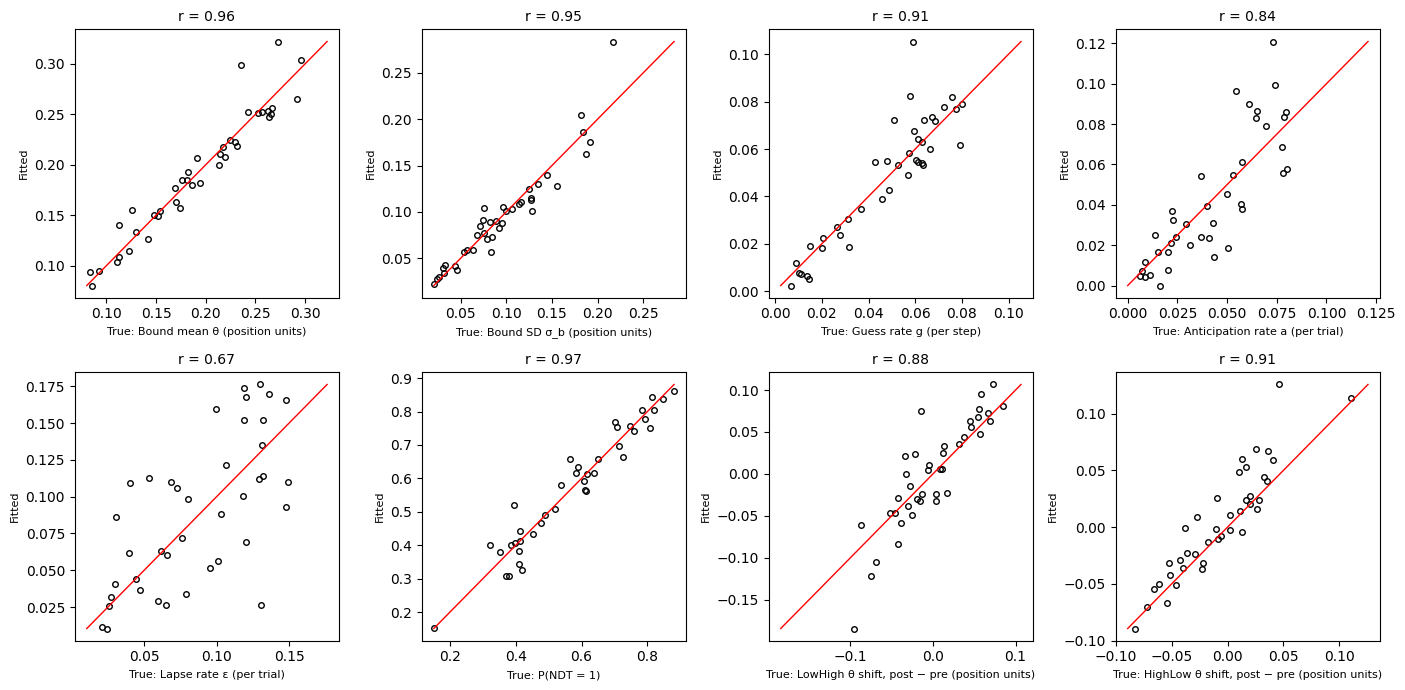

,parameter,r,median error,median |error|
0,bound_mean,0.9592,-0.0036,0.0086
1,bound_std,0.9508,0.0004,0.0069
2,guess_rate,0.9115,-0.0006,0.0057
3,anticipation_rate,0.8388,-0.0004,0.0113
4,lapse_rate,0.6678,0.0008,0.0265
5,ndt1,0.9668,-0.0057,0.0236
6,shift_3,0.8801,0.0052,0.0161
7,shift_4,0.9138,0.0075,0.0100


In [3]:
RECOVERY_PANELS = [
    ('bound_mean', 'Bound mean θ (position units)'),
    ('bound_std', 'Bound SD σ_b (position units)'),
    ('guess_rate', 'Guess rate g (per step)'),
    ('anticipation_rate', 'Anticipation rate a (per trial)'),
    ('lapse_rate', 'Lapse rate ε (per trial)'),
    ('ndt1', 'P(NDT = 1)'),
    ('shift_3', 'LowHigh θ shift, post − pre (position units)'),
    ('shift_4', 'HighLow θ shift, post − pre (position units)'),
]
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
summary = []
for ax, (name, label) in zip(axes.flat, RECOVERY_PANELS):
    t, f = recovery[f'true_{name}'], recovery[f'fit_{name}']
    ax.plot(t, f, 'o', mfc='none', color='k', ms=4)
    lims = [min(t.min(), f.min()), max(t.max(), f.max())]
    ax.plot(lims, lims, 'r-', lw=1)
    r = np.corrcoef(t, f)[0, 1]
    ax.set_title(f'r = {r:.2f}', fontsize=10)
    ax.set_xlabel(f'True: {label}', fontsize=8)
    ax.set_ylabel('Fitted', fontsize=8)
    summary.append({'parameter': name, 'r': r, 'median error': np.median(f - t),
                    'median |error|': np.median(np.abs(f - t))})
plt.tight_layout()
plt.show()
pd.DataFrame(summary).round(4)

**Recovery (2026-10-09, 40 simulated subjects).** Bound mean, bound SD, guess rate
and NDT recover well (r ≈ 0.92–0.97), so guesses and low bounds separate at
these trial counts. The post-CP bound shift recovers with r ≈ 0.9 and a typical
error of ~0.01–0.015 position units, despite only ~20 post-CP commits per
subject per block. The lapse rate is the weakest (r ≈ 0.7), so treat individual
lapse estimates with caution.

These results assume the model is correct; the next step is checking how well
it describes the real data.

## Fits to the fixed blocks (OL, MX, MXSC)

**Conditions (each gets its own bound, guess, anticipation and lapse parameters;
NDT is shared within a subject):**
- **OL:** each (block, SNR) cell. SNR was blocked in OL, and `get_data_table`
  merges each pair of blocked-SNR blocks into one `block_index`.
- **MX:** each block (SNRs are mixed within a block, so the subject cannot set
  a bound per SNR).
- **MXSC:** fixed blocks 1 (Low) and 2 (High) only; the change-point blocks come
  later.

**Trial selection:** `trial_number >= 10` and a recorded choice (trials without
one ran out of the block's step budget). No DT cutoff and no wall-hit exclusion.
Every exclusion is counted below. Fits are cached in `data/processed/`; set
`REFIT = True` to redo them.

In [4]:
REFIT = False
FIT_FILE = Path('../data/processed/stopping_fits_fixed.pkl')
MIN_TRIAL_NUMBER = 10
DATASETS = {'OL': [1, 2, 3], 'MX': [1, 2, 3], 'MXSC': [1, 2]}

tables = {}
for task, blocks in DATASETS.items():
    d = get_data_table(task_type=task, correct_bias=None)
    d = d[d.block_index.isin(blocks)]
    l_early = d.trial_number < MIN_TRIAL_NUMBER
    l_nochoice = d.choice.isna()
    print(f'{task}: {len(d):,} trials in blocks {blocks}; excluded {l_early.sum():,} with trial_number < '
          f'{MIN_TRIAL_NUMBER}, {(l_nochoice & ~l_early).sum():,} more with no choice; '
          f'{d.subject_index.nunique()} subjects')
    d = d[~l_early & ~l_nochoice].copy()
    lev = d.snr.abs().round(3)
    if task == 'OL':
        d['condition'] = [f'B{b:.0f} SNR {s:g}' for b, s in zip(d.block_index, lev)]
    else:
        d['condition'] = [f'B{b:.0f}' for b in d.block_index]
    d['task'] = task
    tables[task] = d

OL: 42,252 trials in blocks [1, 2, 3]; excluded 3,240 with trial_number < 10, 365 more with no choice; 60 subjects


MX: 18,726 trials in blocks [1, 2, 3]; excluded 1,620 with trial_number < 10, 182 more with no choice; 60 subjects


MXSC: 15,184 trials in blocks [1, 2]; excluded 1,134 with trial_number < 10, 132 more with no choice; 65 subjects


In [5]:
if __name__ == '__main__' and (REFIT or not FIT_FILE.exists()):
    fits = pd.concat([fit_stopping_models(d, group_col='condition').assign(task=task)
                      for task, d in tables.items()], ignore_index=True)
    fits.to_pickle(FIT_FILE)
fits = pd.read_pickle(FIT_FILE)
by_subj = fits.groupby(['task', 'subject_index']).first()
print('fits that did not converge, by task:', (~by_subj.success).groupby('task').sum().to_dict())
print('fits that raised:', by_subj.error.notna().sum())

fits that did not converge, by task: {'MX': 0, 'MXSC': 0, 'OL': 3}
fits that raised: 0


### Parameter estimates

Median [interquartile range] across subjects per condition. `θ` and `σ_b` are in
position units, on raw positions (not bias-corrected); OL/MX steps have SD 0.15,
MXSC steps 0.05, so their bounds are on different scales.

In [6]:
PARAMS = ['bound_mean', 'bound_std', 'guess_rate', 'anticipation_rate', 'lapse_rate']

def _med_iqr(x):
    q = np.nanpercentile(x, [25, 50, 75])
    return f'{q[1]:.3f} [{q[0]:.3f}, {q[2]:.3f}]'

param_table = fits.groupby(['task', 'group'])[PARAMS].agg(_med_iqr)
param_table['n subjects'] = fits.groupby(['task', 'group']).size()
display(param_table)
ndt_table = fits.groupby(['task', 'subject_index'])[['ndt_p1', 'ndt_p2', 'ndt_p3']].first().groupby('task').median()
print('Median P(NDT) across subjects:'); display(ndt_table.round(2))

bound_mean             bound_std  \
task group                                                      
MX   B1            0.254 [0.173, 0.345]  0.117 [0.090, 0.162]   
     B2            0.332 [0.229, 0.416]  0.114 [0.073, 0.137]   
     B3            0.296 [0.199, 0.378]  0.077 [0.046, 0.127]   
MXSC B1            0.240 [0.195, 0.317]  0.065 [0.049, 0.111]   
     B2            0.178 [0.108, 0.249]  0.062 [0.039, 0.087]   
OL   B1 SNR 0.333  0.303 [0.237, 0.401]  0.104 [0.075, 0.147]   
     B1 SNR 1      0.188 [0.087, 0.338]  0.112 [0.065, 0.197]   
     B2 SNR 0.333  0.426 [0.346, 0.492]  0.107 [0.084, 0.139]   
     B2 SNR 1      0.235 [0.159, 0.347]  0.082 [0.064, 0.124]   
     B3 SNR 0.333  0.358 [0.279, 0.431]  0.102 [0.051, 0.139]   
     B3 SNR 1      0.170 [0.114, 0.279]  0.065 [0.042, 0.118]   

                             guess_rate     anticipation_rate  \
task group                                                      
MX   B1            0.224 [0.092, 0.318]  0.000 [0.000, 0.056]   
     B2            0.093 [0.048, 0.158]  0.000 [0.000, 0.010]   
     B3            0.084 [0.041, 0.233]  0.000 [0.000, 0.039]   
MXSC B1            0.063 [0.033, 0.140]  0.000 [0.000, 0.021]   
     B2            0.049 [0.030, 0.145]  0.000 [0.000, 0.000]   
OL   B1 SNR 0.333  0.227 [0.106, 0.333]  0.017 [0.000, 0.299]   
     B1 SNR 1      0.198 [0.119, 0.360]  0.067 [0.008, 0.818]   
     B2 SNR 0.333  0.058 [0.038, 0.138]  0.000 [0.000, 0.013]   
     B2 SNR 1      0.154 [0.055, 0.256]  0.000 [0.000, 0.017]   
     B3 SNR 0.333  0.076 [0.025, 0.156]  0.000 [0.000, 0.037]   
     B3 SNR 1      0.129 [0.020, 0.343]  0.000 [0.000, 0.030]   

                             lapse_rate  n subjects  
task group                                           
MX   B1            0.064 [0.019, 0.157]          60  
     B2            0.004 [0.000, 0.065]          60  
     B3            0.019 [0.000, 0.076]          60  
MXSC B1            0.110 [0.000, 0.369]          64  
     B2            0.017 [0.000, 0.057]          61  
OL   B1 SNR 0.333  0.110 [0.040, 0.245]          60  
     B1 SNR 1      0.068 [0.015, 0.150]          60  
     B2 SNR 0.333  0.048 [0.000, 0.136]          60  
     B2 SNR 1      0.017 [0.000, 0.041]          60  
     B3 SNR 0.333  0.002 [0.000, 0.105]          60  
     B3 SNR 1      0.003 [0.000, 0.060]          60

Median P(NDT) across subjects:


,ndt_p1,ndt_p2,ndt_p3
task,,,
MX,0.40,0.52,0.03
MXSC,0.31,0.50,0.13
OL,0.47,0.46,0.03


### Does the model describe the data? (posterior predictive checks)

Each subject is simulated from their own fitted parameters, five times over their
real trials (same condition, step statistics and trial count). Real (black) vs.
simulated (red), pooled over subjects.

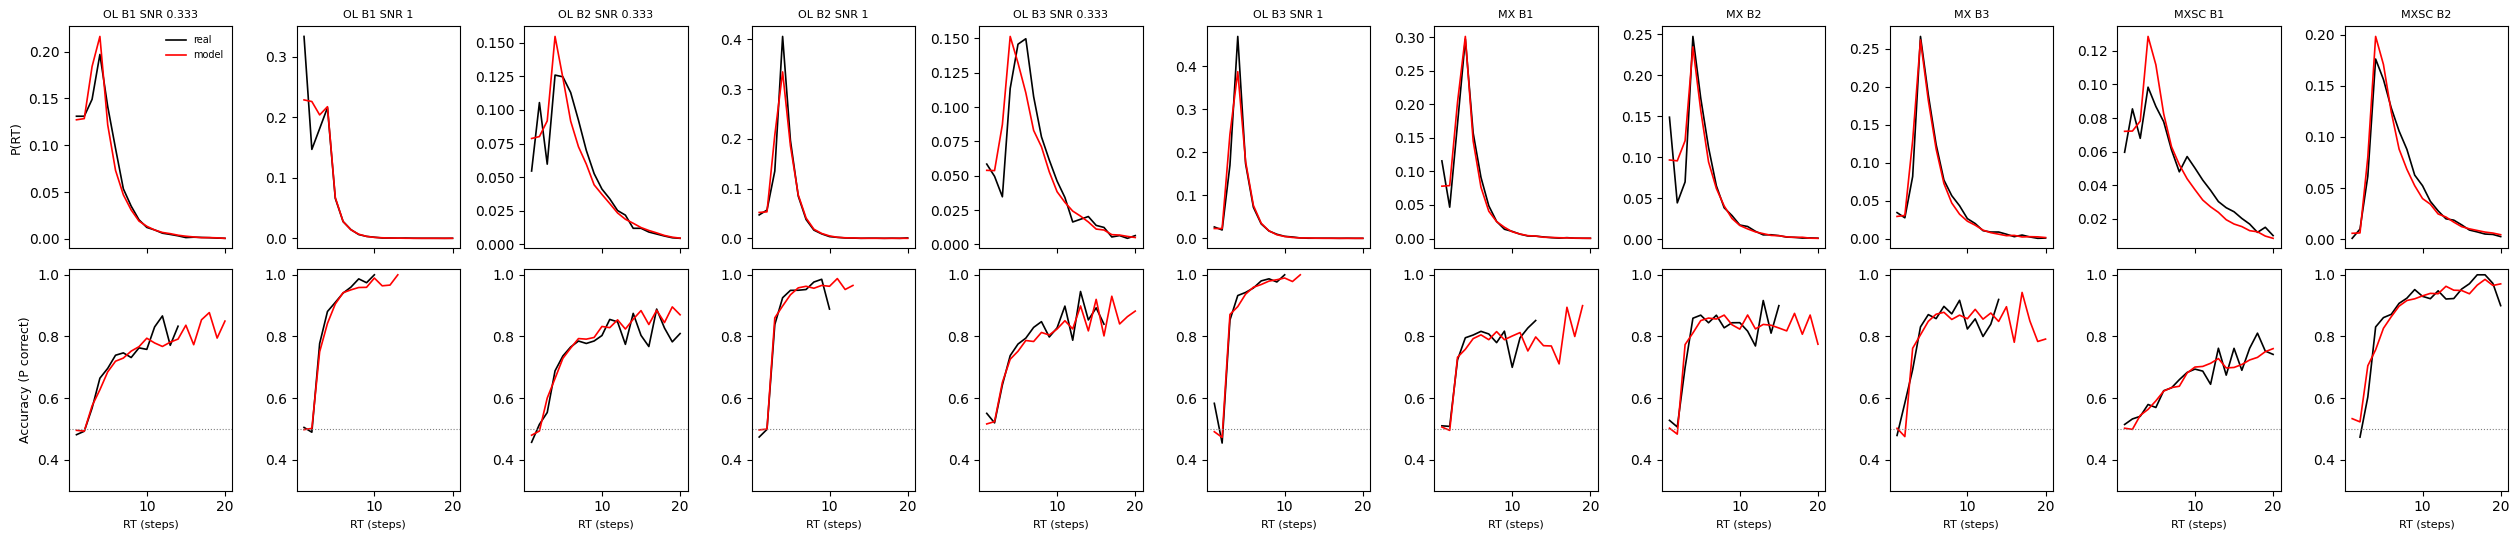

In [7]:
PPC_SEED = 11
PPC_REPS = 5
sims = {task: simulate_stopping_data_table(d, fits[fits.task == task], group_col='condition',
                                           num_reps=PPC_REPS, rng=np.random.default_rng(PPC_SEED))
        for task, d in tables.items()}

MAX_RT_SHOW = 20
rt_ax = np.arange(1, MAX_RT_SHOW + 1)
conds = [(task, c) for task, d in tables.items() for c in sorted(d.condition.unique())]
fig, axes = plt.subplots(2, len(conds), figsize=(2.3 * len(conds), 5.5), sharex=True)
for ci, (task, c) in enumerate(conds):
    real = tables[task][tables[task].condition == c]
    sim = sims[task][sims[task].condition == c]
    ax = axes[0, ci]
    for t, col in ((real, 'k'), (sim, 'r')):
        p_rt = t.RT.value_counts(normalize=True).reindex(rt_ax, fill_value=0)
        ax.plot(rt_ax, p_rt, '-', color=col, lw=1.2)
    ax.set_title(f'{task} {c}', fontsize=8)
    ax = axes[1, ci]
    for t, col in ((real, 'k'), (sim, 'r')):
        acc = t.groupby('RT').correct.agg(['mean', 'size']).reindex(rt_ax)
        acc.loc[acc['size'] < 20, 'mean'] = np.nan
        ax.plot(rt_ax, acc['mean'], '-', color=col, lw=1.2)
    ax.axhline(0.5, color='gray', ls=':', lw=0.8)
    ax.set_ylim(0.3, 1.02)
    ax.set_xlabel('RT (steps)', fontsize=8)
axes[0, 0].set_ylabel('P(RT)', fontsize=9)
axes[1, 0].set_ylabel('Accuracy (P correct)', fontsize=9)
axes[0, 0].legend(['real', 'model'], fontsize=7, frameon=False)
plt.tight_layout()
plt.show()

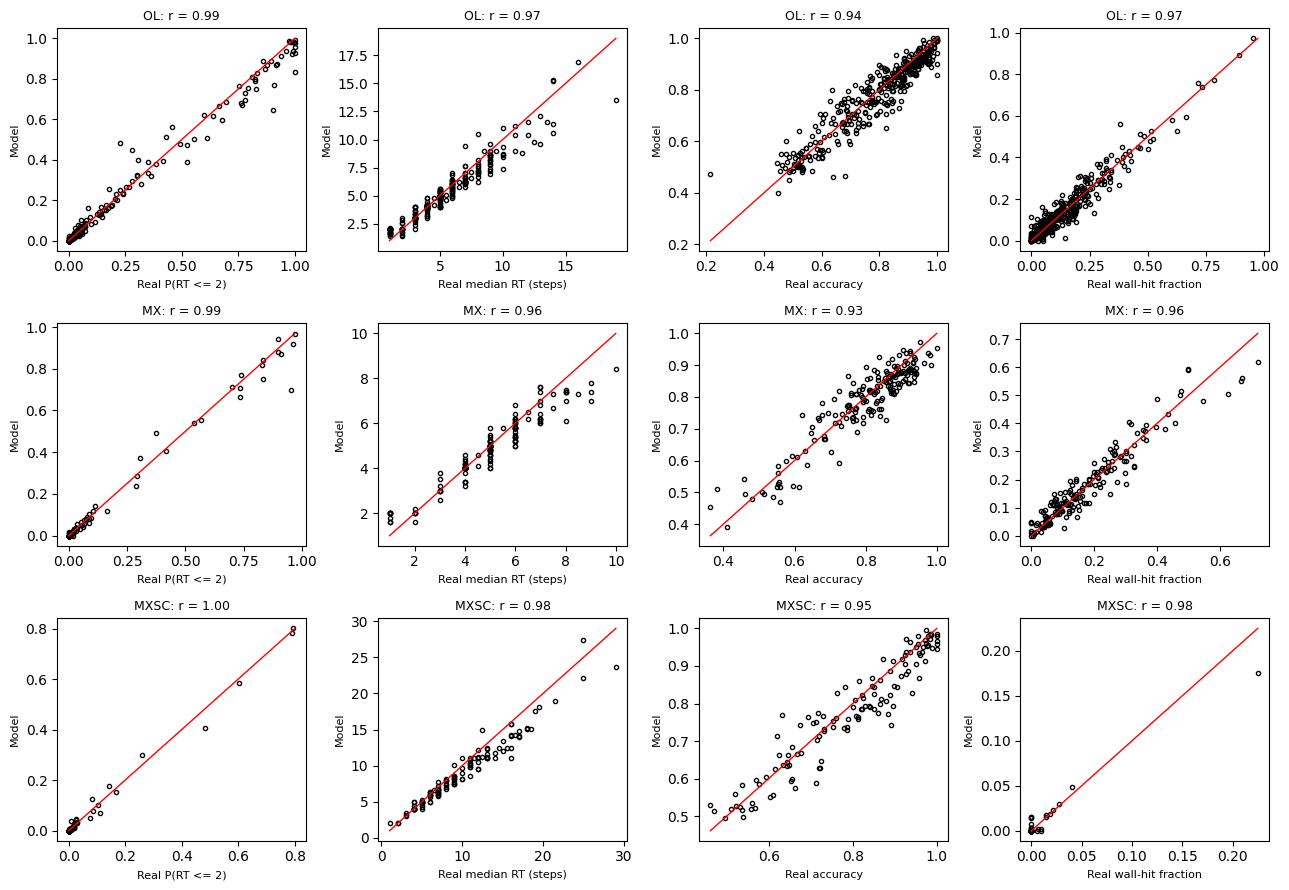

,task,statistic,r,median real,median model
0,OL,P(RT <= 2),0.994,0.000,0.000
1,OL,median RT (steps),0.966,4.000,4.000
2,OL,accuracy,0.940,0.827,0.818
3,OL,wall-hit fraction,0.966,0.111,0.112
4,MX,P(RT <= 2),0.994,0.000,0.000
5,MX,median RT (steps),0.963,5.000,4.600
6,MX,accuracy,0.928,0.831,0.819
7,MX,wall-hit fraction,0.956,0.137,0.137
8,MXSC,P(RT <= 2),0.996,0.000,0.000
9,MXSC,median RT (steps),0.977,9.000,8.000


In [8]:
# Per-subject summaries, real vs. model (mean over the simulated replicates).
def _subject_stats(t):
    g = t.groupby(['subject_index', 'condition'])
    return pd.DataFrame({'P(RT <= 2)': g.RT.apply(lambda r: np.mean(r <= 2)),
                         'median RT (steps)': g.RT.median(),
                         'accuracy': g.correct.mean(),
                         'wall-hit fraction': g.wall_hit.mean()})

STAT_NAMES = ['P(RT <= 2)', 'median RT (steps)', 'accuracy', 'wall-hit fraction']
fig, axes = plt.subplots(len(DATASETS), len(STAT_NAMES), figsize=(13, 9))
ppc_rows = []
for ti, task in enumerate(DATASETS):
    real = _subject_stats(tables[task])
    sim = sims[task].groupby('rep').apply(_subject_stats).groupby(level=[1, 2]).mean()
    both = real.join(sim, rsuffix=' model')
    for si, s in enumerate(STAT_NAMES):
        ax = axes[ti, si]
        ax.plot(both[s], both[f'{s} model'], 'o', mfc='none', color='k', ms=3)
        lims = [np.nanmin(both[[s, f'{s} model']].values), np.nanmax(both[[s, f'{s} model']].values)]
        ax.plot(lims, lims, 'r-', lw=1)
        r = both[[s, f'{s} model']].corr().iloc[0, 1]
        ax.set_title(f'{task}: r = {r:.2f}', fontsize=9)
        ax.set_xlabel(f'Real {s}', fontsize=8)
        ax.set_ylabel('Model', fontsize=8)
        ppc_rows.append({'task': task, 'statistic': s, 'r': r,
                         'median real': np.nanmedian(both[s]), 'median model': np.nanmedian(both[f'{s} model'])})
plt.tight_layout()
plt.show()
pd.DataFrame(ppc_rows).round(3)

### How many guesses survive the standard DT ≥ 2 filter?

In the simulated data we know which commits were bound crossings, guesses or
anticipations. Apply the paper's filter as it would be applied to real data:
`DT = RT − NDT − 1 >= 2`, using each subject's NDT as inferred by `get_bounds` on
their real data, and excluding wall hits (the `get_good_trial_array` filter).

In [9]:
guess_rows = []
for task, d in tables.items():
    ndt_inferred = (d.RT - d.DT - 1).groupby(d.subject_index).max()   # get_bounds' per-subject lag
    s = sims[task].copy()
    s['DT_inferred'] = s.RT - s.subject_index.map(ndt_inferred) - 1
    l_pass = (s.DT_inferred >= 2) & ~s.wall_hit
    for c, sc in s.groupby('condition'):
        lp = l_pass.loc[sc.index]
        frac_all = sc.commit_type.value_counts(normalize=True)
        frac_pass = sc[lp].commit_type.value_counts(normalize=True)
        guess_rows.append({'task': task, 'condition': c,
                           'guess+antic., all trials': frac_all.get('guess', 0) + frac_all.get('anticipation', 0),
                           'guess+antic., passing filter': frac_pass.get('guess', 0) + frac_pass.get('anticipation', 0),
                           'fraction of trials passing': lp.mean()})
pd.DataFrame(guess_rows).round(3)

,task,condition,"guess+antic., all trials","guess+antic., passing filter",fraction of trials passing
0,OL,B1 SNR 0.333,0.615,0.505,0.450
1,OL,B1 SNR 1,0.585,0.158,0.220
2,OL,B2 SNR 0.333,0.470,0.384,0.591
3,OL,B2 SNR 1,0.285,0.202,0.430
4,OL,B3 SNR 0.333,0.420,0.366,0.642
5,OL,B3 SNR 1,0.196,0.170,0.464
6,MX,B1,0.421,0.352,0.429
7,MX,B2,0.396,0.278,0.454
8,MX,B3,0.291,0.284,0.555
9,MXSC,B1,0.672,0.598,0.720


### Interpretation (2026-10-09, first fixed-block fits)

- **Fit quality is good.** The model reproduces RT distributions, accuracy vs. RT
  (including chance accuracy at RT ≤ 2), and per-subject P(RT ≤ 2), median RT,
  accuracy and wall-hit fraction (r = 0.93–1.0). The MXSC Low block (B1) is the
  weakest: the model's RTs are slightly too short and its accuracy slightly low.
- **The model leans heavily on the "guess" process:** median guess rates of
  0.05–0.22 per step, so in simulation 20–67% of commits are guesses or
  anticipations, and 16–60% of the trials that pass the paper's `DT >= 2` filter.
- **Caution: "guess" is a catch-all.** In this model a bound can only fire when
  the pigeon reaches a new maximum distance from center, so *any* commit that
  doesn't, from whatever cause, is attributed to the guess process. Causes that
  aren't guessing include a bound that collapses over the trial (urgency),
  noisy perception of the position, or responding to something other than
  position (e.g., the direction of the last step, which the pigeon's sprite
  shows). These need to be ruled out before calling these commits guesses.
- **Some subjects respond almost entirely at RT ≤ 2 in some blocks**
  (anticipation-rate IQR up to 0.82 in OL B1, SNR 1).